**PUNTO 1:**

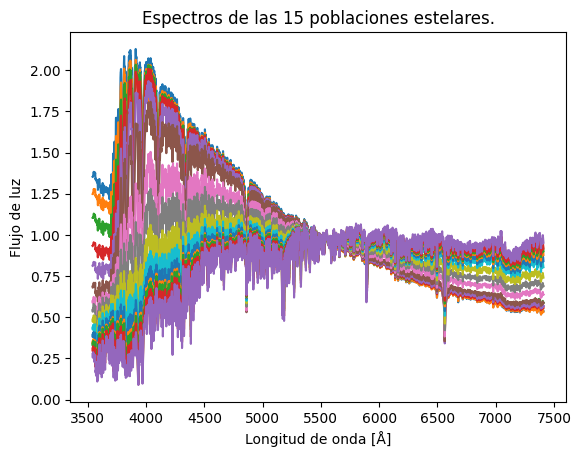

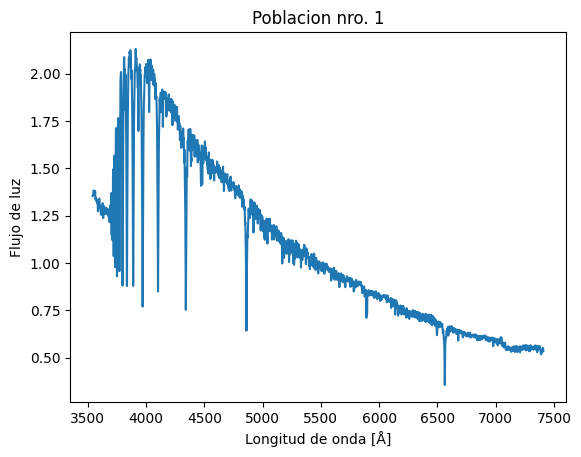

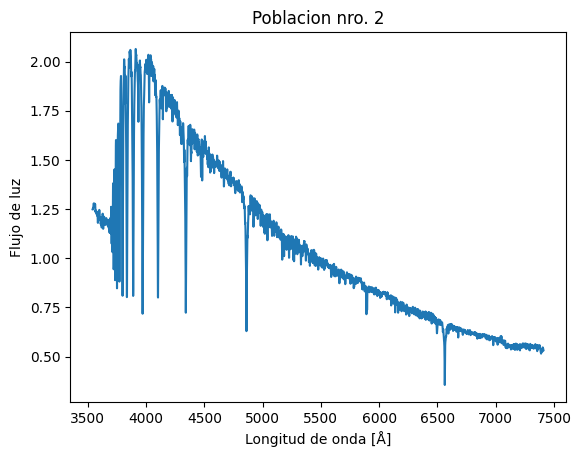

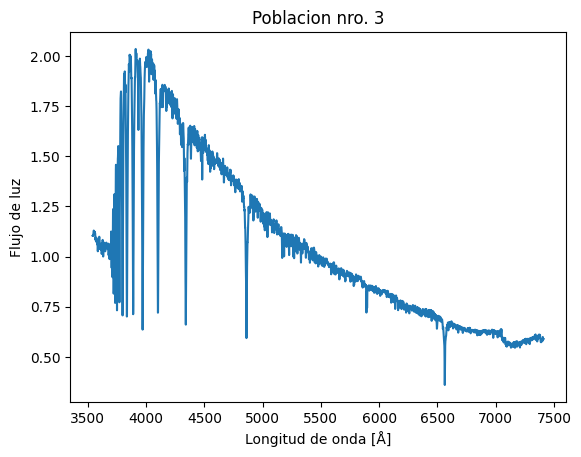

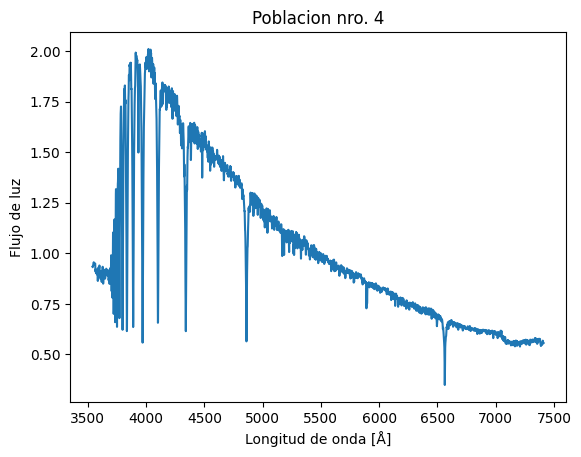

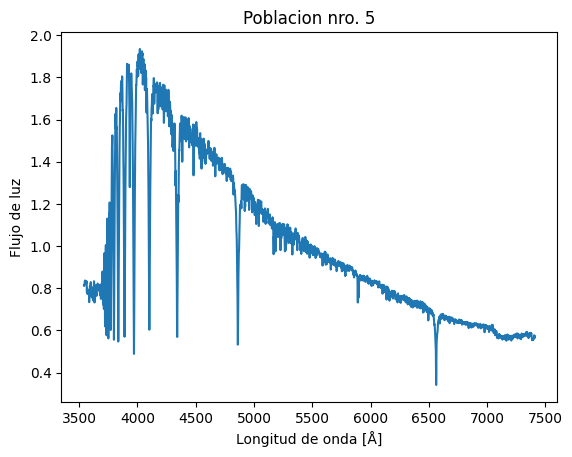

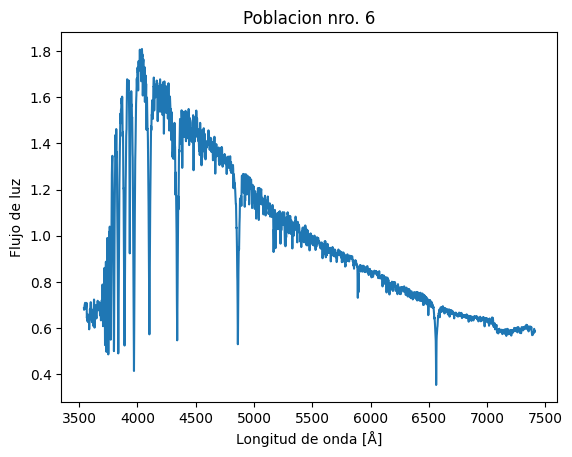

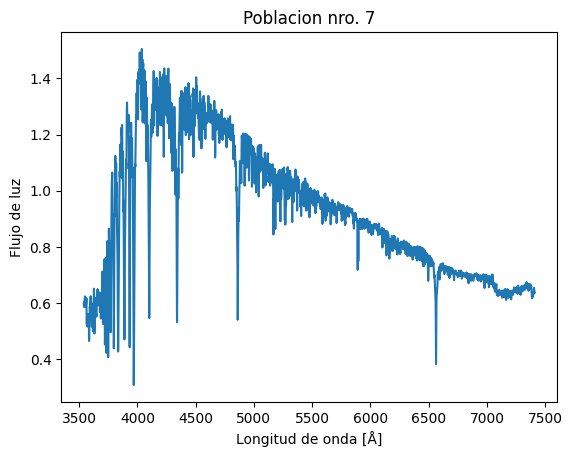

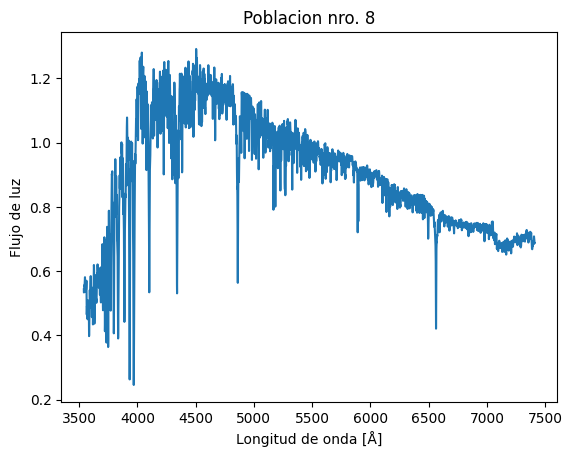

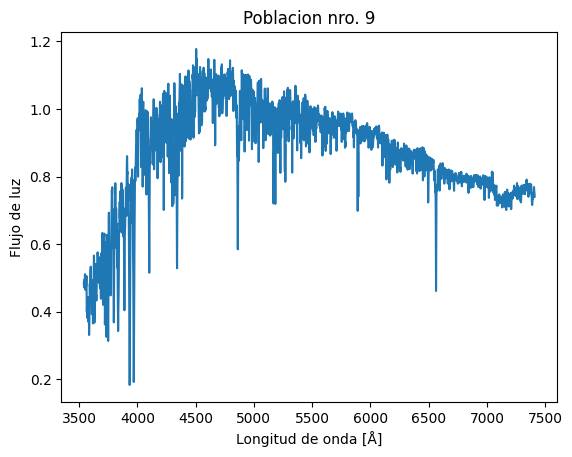

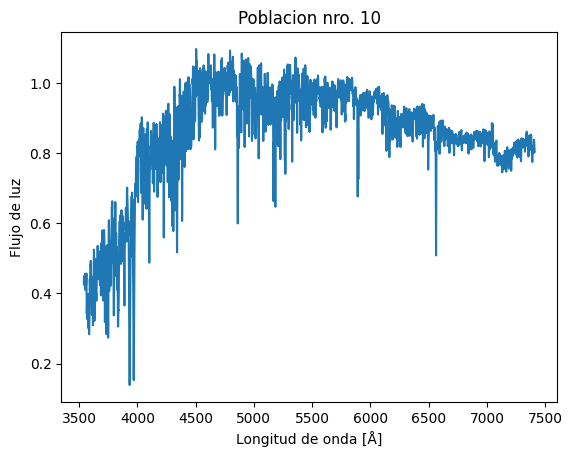

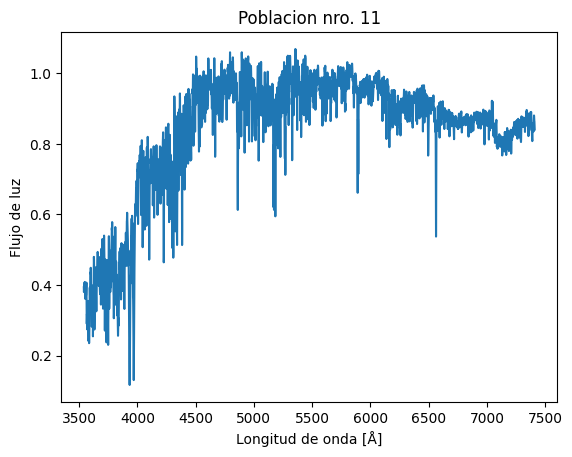

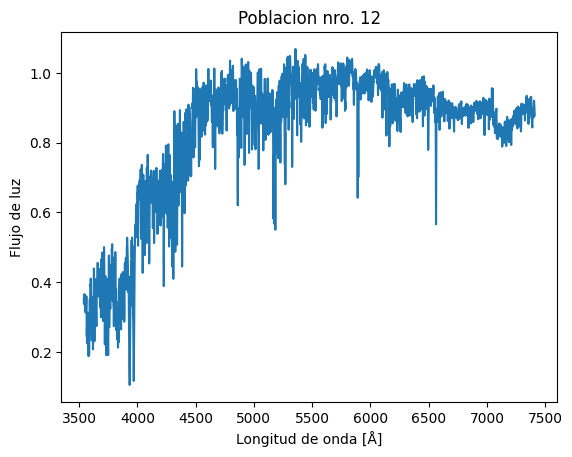

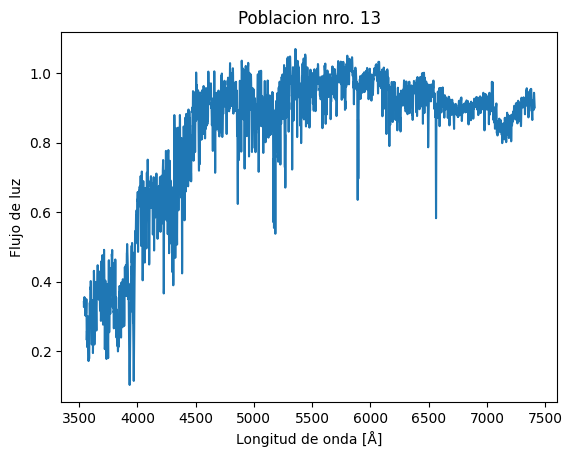

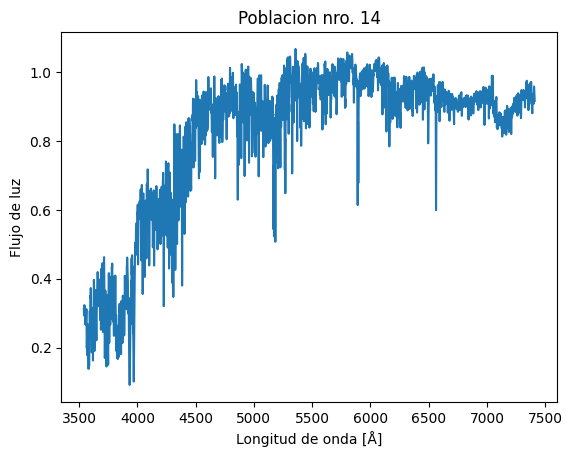

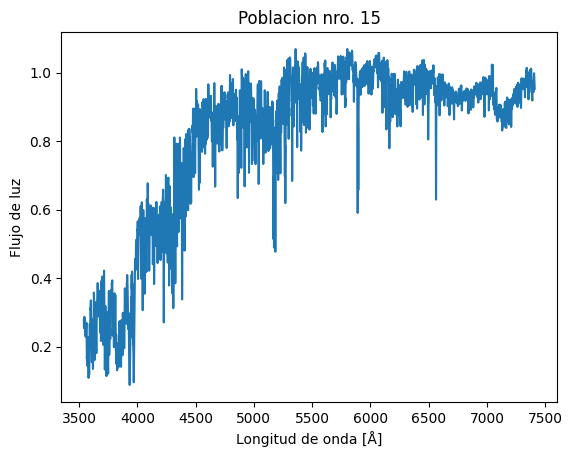

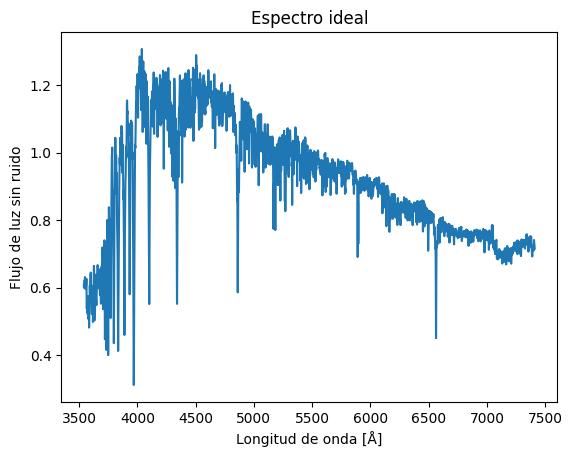

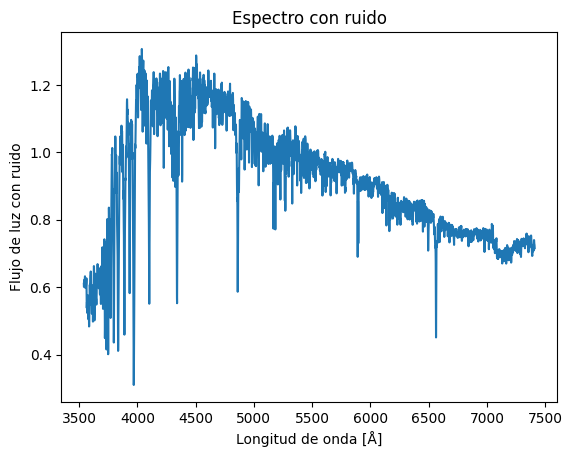

In [24]:
import numpy as np
import matplotlib.pyplot as plt
archivomatriz = open("C:/Users/guina/Desktop/Udesa/Guias/4. F. de la IA/TP2_Metodos/Archivos/longitudondayA.csv", "r")
archivomatriz.readline()
archivo_b_ideal = open("C:/Users/guina/Desktop/Udesa/Guias/4. F. de la IA/TP2_Metodos/Archivos/espectroideal.csv", "r")
archivo_b_ideal.readline()
archivo_b_ruidoso = open("C:/Users/guina/Desktop/Udesa/Guias/4. F. de la IA/TP2_Metodos/Archivos/espectro_ruido.csv", "r")
archivo_b_ruidoso.readline()
A = np.zeros((4300,16))
b_ideal = np.zeros((4300,2))
b_ruidoso = np.zeros((4300,2))
#Pasando a matriz el csv de A
i=0
for linea in archivomatriz:
    valores = linea.strip().split(',')
    for j in range(16):
        A[i,j] = float(valores[j])
    i += 1
archivomatriz.close()

#Pasando a amtriz el csv de b ideal
i=0
for linea in archivo_b_ideal:
    valores = linea.strip().split(',')
    for j in range(2):
        b_ideal[i,j] = float(valores[j])
    i += 1
archivo_b_ideal.close()

#Pasando a matriz el csv de b ruidoso
i=0
for linea in archivo_b_ruidoso:
    valores = linea.strip().split(',')
    for j in range(2):
        b_ruidoso[i,j] = float(valores[j])
    i += 1
archivo_b_ruidoso.close()
    
x = A[:,0]
for poblacion in range(15):
    y = A[:,poblacion+1]
    plt.plot(x,y,label="Pob. " + str(poblacion + 1))

plt.xlabel("Longitud de onda [Å]")
plt.ylabel("Flujo de luz")
plt.title("Espectros de las 15 poblaciones estelares.")
plt.show()
for poblacion in range(15):
    y = A[:,poblacion+1]
    plt.plot(x,y)
    plt.xlabel("Longitud de onda [Å]")
    plt.ylabel("Flujo de luz")
    plt.title("Poblacion nro. " + str(poblacion+1))
    plt.show()

x = b_ideal[:,0]
y = b_ideal[:,1]
plt.plot(x,y)
plt.xlabel("Longitud de onda [Å]")
plt.ylabel("Flujo de luz sin ruido")
plt.title("Espectro ideal")
plt.show()

x = b_ruidoso[:,0]
y = b_ruidoso[:,1]
plt.plot(x,y)
plt.xlabel("Longitud de onda [Å]")
plt.ylabel("Flujo de luz con ruido")
plt.title("Espectro con ruido")
plt.show()



Cada elemento a_ij de la matriz **A** representa el flujo de luz emitido por la poblacion estelar j en la longitud de onda i.
- i: indica una de las 4300 longitudes de onda.
- j: indica una de las 15 poblaciones estelares.
Por lo tanto, la matriz contiene los espectros de las 15 poblaciones estelares, donde cada fila corresponde a una longitud de onda y cada columna a una poblacion de determinada edad.

**PUNTO 2:**

Coeficientes estimados:  [0.03165392 0.04057853 0.04334498 0.0622342  0.07061119 0.08507607
 0.08340779 0.10330264 0.088648   0.11579838 0.0946049  0.03216057
 0.04234708 0.07564544 0.03057274]


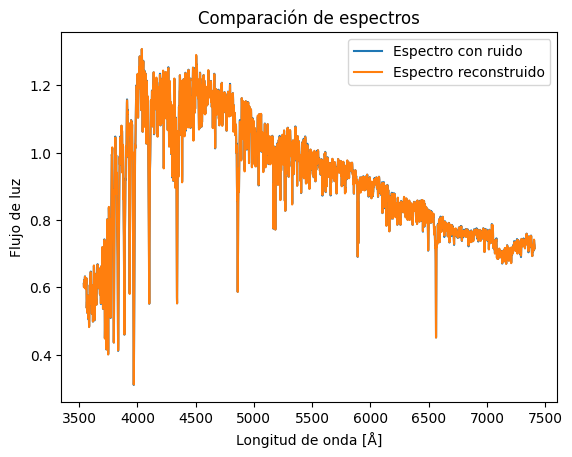

Error:  0.11438921469687803
Error relativo:  0.0018743601934080242


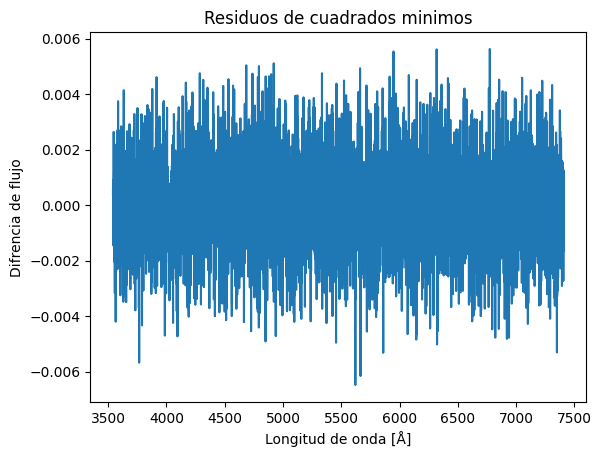

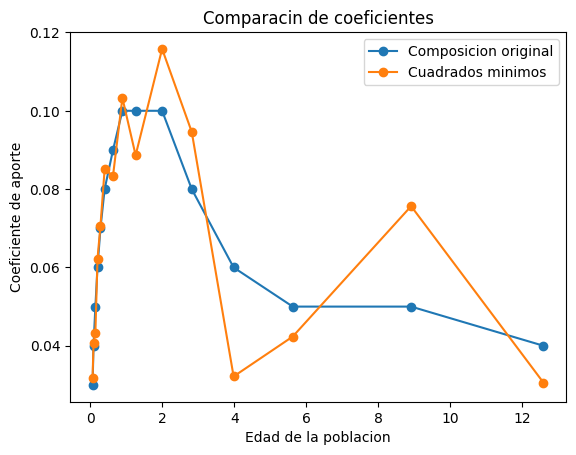

Error en los coeficientes: 0.048008108903105716


In [25]:
A_espectros = A[:, 1:]

b = b_ruidoso[:,1]
AtA = A_espectros.T @ A_espectros
Atb = A_espectros.T @ b
x_estimado = np.linalg.solve(AtA, Atb)
print("Coeficientes estimados: ", x_estimado)

b_reconstruido = A_espectros @ x_estimado
plt.plot(b_ruidoso[:,0], b, label="Espectro con ruido")
plt.plot(b_ruidoso[:,0], b_reconstruido, label="Espectro reconstruido")

plt.xlabel("Longitud de onda [Å]")
plt.ylabel("Flujo de luz")
plt.title("Comparación de espectros")
plt.legend()
plt.show()

residuo = b - b_reconstruido
error = np.linalg.norm(residuo)
error_rel = error / np.linalg.norm(b)

print("Error: ", error)
print("Error relativo: ", error_rel)

plt.plot(b_ruidoso[:, 0], residuo)
plt.xlabel("Longitud de onda [Å]")
plt.ylabel("Difrencia de flujo")
plt.title("Residuos de cuadrados minimos")
plt.show()

archivo_xreal = open("C:/Users/guina/Desktop/Udesa/Guias/4. F. de la IA/TP2_Metodos/Archivos/x_real.csv", "r")
archivo_xreal.readline()
xreal = np.zeros((15, 2))
i = 0
for linea in archivo_xreal:
    valores = linea.strip().split(",")
    for j in range(2):
        xreal[i, j] = float(valores[j])
    i += 1

archivo_xreal.close()
edades = xreal[:, 0]
x_real = xreal[:, 1]
plt.plot(edades, x_real, "o-", label="Composicion original")
plt.plot(edades, x_estimado, "o-", label="Cuadrados minimos")

plt.xlabel("Edad de la poblacion")
plt.ylabel("Coeficiente de aporte")
plt.title("Comparacin de coeficientes")
plt.legend()
plt.show()

print("Error en los coeficientes:", np.linalg.norm(x_estimado - x_real))
